In [1]:
import pandas as pd

# Читаем ВСЕ листы Excel-файла сразу.
# sheet_name=None значит "все листы"; получится словарь: {имя_листа: таблица}
sheets = pd.read_excel("../data/sales_raw.xlsx", sheet_name=None)

# Смотрим, что загрузилось: имя листа, размер (строки, столбцы) и первые 3 строки
for name, df in sheets.items():
    print(name, df.shape)
    print(df.head(3))
    print("-" * 60)

Продажи (730, 10)
   Order_ID      Приоритет  Количество   Выручка Метод доставки  Прибыль  \
0       643           High          21  2 781.82    Express Air  -695.26   
1      8995           High          35  2 781.83    Express Air   737.94   
2      9127  Not Specified           7  2 781.84    Express Air  -329.49   

       Покупатель                 Регион  \
0  Monica Federle                Nunavut   
1      Beth Paige  Northwest Territories   
2     Bryan Davis  Northwest Territories   

                                             Продукт Упаковка продукта  
0              SAFCO Commercial Wire Shelving, Black         Large Box  
1       Luxo Professional Combination Clamp-On Lamps         Large Box  
2  Tennsco Snap-Together Open Shelving Units, Sta...         Large Box  
------------------------------------------------------------
СПР_стоимость_доставки (2, 2)
  Метод доставки  Стоимость доставки
0    Express Air                  10
1    Regular Air                   5
------

In [2]:
# --- Берём каждую таблицу из словаря sheets в отдельную переменную ---
# .copy() делает копию, чтобы не испортить исходные данные
sales     = sheets["Продажи"].copy()
delivery  = sheets["СПР_стоимость_доставки"].copy()
dates     = sheets["СПР_даты_заказа"].copy()
products  = sheets["СПР_продукты"].copy()
customers = sheets["СПР_покупатели"].copy()
managers  = sheets["СПР_Менеджеры"].copy()

# --- Функция чистки: одинаковые шаги для всех таблиц ---
def clean(df):
    df = df.dropna(how="all").copy()   # удалить полностью пустые строки
    for col in df.columns:
        # трогаем только НЕ числовые и НЕ датовые столбцы
        if not pd.api.types.is_numeric_dtype(df[col]) and \
           not pd.api.types.is_datetime64_any_dtype(df[col]):
            # сначала всё в текст (688 -> "688"), потом убираем пробелы
            df[col] = df[col].astype(str).str.strip()
    return df

sales, delivery, dates, products, customers, managers = [
    clean(t) for t in [sales, delivery, dates, products, customers, managers]
]

# --- Выручка и Прибыль: текст -> число ---
for col in ["Выручка", "Прибыль"]:
    sales[col] = (
        sales[col].astype(str)
        .str.replace("\xa0", "", regex=False)  # убрать неразрывный пробел
        .str.replace(" ", "", regex=False)     # и обычный, на всякий случай
        .astype(float)                          # превратить в число
    )

# --- Дубли в справочниках (как "Удалить дубликаты" по ключу) ---
products  = products.drop_duplicates(subset="Продукт")
customers = customers.drop_duplicates(subset="Покупатель")
dates     = dates.drop_duplicates(subset="Order_ID")

# --- Проверка ---
print(sales.dtypes)
print()
for name, t in [("Продажи", sales), ("Продукты", products), ("Покупатели", customers),
                ("Менеджеры", managers), ("Даты", dates), ("Доставка", delivery)]:
    print(f"{name:12} {t.shape}")

Order_ID               int64
Приоритет                str
Количество             int64
Выручка              float64
Метод доставки           str
Прибыль              float64
Покупатель               str
Регион                   str
Продукт                  str
Упаковка продукта        str
dtype: object

Продажи      (730, 10)
Продукты     (445, 3)
Покупатели   (173, 2)
Менеджеры    (6, 2)
Даты         (571, 2)
Доставка     (2, 2)


In [3]:
# Приклеиваем к продажам все справочники.
# validate="many_to_one" = проверка, что в справочнике ключ уникален
# (это то же самое, что связь "многие к одному" в Power BI).
# Если в справочнике окажется дубль, pandas сразу выдаст ошибку.
df = (
    sales
    .merge(dates,     on="Order_ID",       how="left", validate="many_to_one")
    .merge(customers, on="Покупатель",     how="left", validate="many_to_one")
    .merge(products,  on="Продукт",        how="left", validate="many_to_one")
    .merge(managers,  on="Регион",         how="left", validate="many_to_one")
    .merge(delivery,  on="Метод доставки", how="left", validate="many_to_one")
)

print("Строк после объединения:", len(df))   # должно остаться 730
print()
print("Пустые значения по столбцам:")
print(df.isna().sum())                        # везде должны быть нули

Строк после объединения: 730

Пустые значения по столбцам:
Order_ID                 0
Приоритет                0
Количество               0
Выручка                  0
Метод доставки           0
Прибыль                  0
Покупатель               0
Регион                   0
Продукт                  0
Упаковка продукта        0
Дата                     0
Сегмент покупателя       0
Категория продукта       0
Подкатегория продукта    0
Менеджер                 0
Стоимость доставки       0
dtype: int64


In [4]:
revenue   = df["Выручка"].sum()                 # = SUM(Продажи[Выручка])
profit    = df["Прибыль"].sum()                 # = SUM(Продажи[Прибыль])
margin    = profit / revenue                    # = DIVIDE([Прибыль], [Выручка])
akb       = df["Покупатель"].nunique()          # = DISTINCTCOUNT(Продажи[Покупатель])
orders    = df["Order_ID"].nunique()            # количество уникальных заказов
avg_check = revenue / orders                    # = Средний чек
logistics = df["Стоимость доставки"].sum()      # = SUMX(Продажи, RELATED(...))

kpi = pd.Series({
    "Выручка": revenue,
    "Прибыль": profit,
    "Рентабельность, %": margin * 100,
    "АКБ": akb,
    "Заказов": orders,
    "Средний чек": avg_check,
    "Затраты на логистику": logistics,
}).round(2)

kpi

Выручка                 1103256.31
Прибыль                  253784.61
Рентабельность, %            23.00
АКБ                         173.00
Заказов                     571.00
Средний чек                1932.15
Затраты на логистику       4405.00
dtype: float64

In [5]:
monthly = (
    df.groupby(df["Дата"].dt.month)["Выручка"]   # группируем по номеру месяца
      .sum()
      .round(2)
)
monthly

Дата
1    311443.51
2    198635.98
3    361369.10
4    231807.72
Name: Выручка, dtype: float64

In [6]:
# 1) Сначала считаем прибыль по каждому ЗАКАЗУ целиком (сумма по всем его товарам)
order_profit = (
    df.groupby(["Менеджер", "Order_ID"], as_index=False)["Прибыль"].sum()
)

# 2) Оставляем только заказы с итоговой прибылью < 0
loss_orders = order_profit[order_profit["Прибыль"] < 0]

# 3) По каждому менеджеру: сумма убытка и количество таких заказов
loss_by_manager = (
    loss_orders.groupby("Менеджер")
    .agg(Убыток=("Прибыль", "sum"), Заказов=("Order_ID", "count"))
    .sort_values("Заказов", ascending=False)
    .round(2)
)
loss_by_manager

,Убыток,Заказов
Менеджер,,
Мерингольд Ванесса,-15523.33,83
Семейкин Владислав,-14763.31,65
Иванов Петр,-9789.04,59
Конюхов Добромир,-4656.25,33
Крестьянин Арчибальд,-3204.03,26
Петров Иван,-3749.40,13


In [7]:
# Сколько раз продавался каждый продукт?
sales_count = df.groupby("Продукт").size()   # size() = количество строк в группе
sales_count.value_counts().sort_index()       # сколько продуктов продались 1 раз, 2 раза...

1    251
2    132
3     38
4     19
5      5
Name: count, dtype: int64

In [8]:
# 1) Выручка по подкатегориям, от большей к меньшей
sub = (
    df.groupby("Подкатегория продукта")["Выручка"].sum()
      .sort_values(ascending=False)
      .to_frame("Выручка")                    # превращаем в таблицу с одним столбцом
)

# 2) ABC: накопленная доля и классы (пороги 70% / 90%, как в Power BI)
sub["Доля накоп."] = sub["Выручка"].cumsum() / sub["Выручка"].sum()
sub["ABC"] = pd.cut(sub["Доля накоп."],
                    bins=[0, 0.7, 0.9, float("inf")],
                    labels=["A", "B", "C"])

# 3) Таблица "подкатегория x месяц" с выручкой (0, если продаж не было)
monthly_sub = df.pivot_table(
    index="Подкатегория продукта",
    columns=df["Дата"].dt.month,
    values="Выручка",
    aggfunc="sum",
    fill_value=0,
)

# 4) XYZ: коэффициент вариации по месяцам
sub["CV"] = monthly_sub.std(axis=1, ddof=0) / monthly_sub.mean(axis=1)
sub["XYZ"] = pd.cut(sub["CV"],
                    bins=[0, 0.3, 0.6, float("inf")],
                    labels=["X", "Y", "Z"])

# 5) Итоговый класс: "AX", "BY" и т.д.
sub["Класс"] = sub["ABC"].astype(str) + sub["XYZ"].astype(str)

sub.round(3)

,Выручка,Доля накоп.,ABC,CV,XYZ,Класс
Подкатегория продукта,,,,,,
Telephones and Communication,256536.17,0.233,A,0.124,X,AX
Copiers and Fax,159614.61,0.377,A,0.940,Z,AZ
Binders and Binder Accessories,106501.62,0.474,A,0.601,Z,AZ
Appliances,100349.75,0.565,A,0.482,Y,AY
Storage & Organization,97342.80,0.653,A,0.330,Y,AY
Office Furnishings,82135.44,0.727,B,0.414,Y,BY
Office Machines,80050.06,0.800,B,0.504,Y,BY
Computer Peripherals,65475.00,0.859,B,0.285,X,BX
Paper,48963.04,0.904,C,0.290,X,CX


In [9]:
# "Сегодняшняя" дата для расчёта давности = день после последней покупки в данных
ref_date = df["Дата"].max() + pd.Timedelta(days=1)
print("Дата отсчёта:", ref_date.date())

rfm = df.groupby("Покупатель").agg(
    last_order=("Дата", "max"),        # дата последней покупки
    F=("Order_ID", "nunique"),         # сколько разных заказов
    M=("Выручка", "sum"),              # сколько денег принёс
)
rfm["R"] = (ref_date - rfm["last_order"]).dt.days   # дней с последней покупки

rfm.describe().round(1)

Дата отсчёта: 2022-04-30


,last_order,F,M,R
count,173,173.0,173.0,173.0
mean,2022-03-24 16:13:52.369942,3.3,6377.2,36.3
min,2022-01-02 00:00:00,1.0,14.8,1.0
25%,2022-03-10 00:00:00,1.0,1006.1,8.0
50%,2022-04-02 00:00:00,3.0,3182.2,28.0
75%,2022-04-22 00:00:00,5.0,8938.3,51.0
max,2022-04-29 00:00:00,13.0,48039.1,118.0
std,NaN,2.5,7998.4,33.4


In [10]:
# --- Баллы ---
# R: до 14 дней = 3 (недавно), 15-45 дней = 2, больше 45 = 1 (давно)
rfm["R_score"] = pd.cut(rfm["R"], [0, 14, 45, float("inf")], labels=[3, 2, 1]).astype(int)
# F: 1 заказ = 1, 2-4 заказа = 2, 5 и больше = 3
rfm["F_score"] = pd.cut(rfm["F"], [0, 1, 4, float("inf")], labels=[1, 2, 3]).astype(int)
# M: делим покупателей на три равные по численности группы по выручке
rfm["M_score"] = pd.qcut(rfm["M"], 3, labels=[1, 2, 3]).astype(int)

# RFM-код, например "333" = лучший клиент
rfm["RFM"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

# --- Сегменты: правила проверяются сверху вниз, срабатывает первое подходящее ---
def segment(row):
    if row.R_score == 3 and row.F_score == 3: return "Чемпионы"
    if row.F_score == 3:                      return "Лояльные"
    if row.R_score == 3 and row.F_score == 1: return "Новые"
    if row.R_score == 1 and row.F_score >= 2: return "Под угрозой ухода"
    if row.R_score == 1 and row.F_score == 1: return "Потерянные"
    return "Требуют внимания"

rfm["Сегмент"] = rfm.apply(segment, axis=1)

# --- Итог по сегментам ---
seg = rfm.groupby("Сегмент").agg(
    Клиентов=("M", "size"),
    Выручка=("M", "sum"),
    Заказов_в_среднем=("F", "mean"),
    Дней_с_покупки=("R", "mean"),
)
seg["Доля выручки, %"] = seg["Выручка"] / seg["Выручка"].sum() * 100
seg.sort_values("Выручка", ascending=False).round(1)

,Клиентов,Выручка,Заказов_в_среднем,Дней_с_покупки,"Доля выручки, %"
Сегмент,,,,,
Чемпионы,26,328837.6,7.1,6.0,29.8
Лояльные,20,280752.1,6.3,36.3,25.4
Требуют внимания,64,277356.5,2.6,20.0,25.1
Под угрозой ухода,22,140207.7,2.3,71.9,12.7
Потерянные,30,58287.1,1.0,82.6,5.3
Новые,11,17815.2,1.0,6.1,1.6


In [11]:
# Аномалия: прибыль больше выручки (рентабельность > 100% невозможна)
df["Аномалия"] = df["Прибыль"] > df["Выручка"]

print("Аномальных строк:", df["Аномалия"].sum())
print("Их прибыль:", df.loc[df["Аномалия"], "Прибыль"].sum().round(2))
print()
df.loc[df["Аномалия"], ["Order_ID", "Выручка", "Прибыль", "Подкатегория продукта"]] \
  .sort_values("Прибыль", ascending=False)

Аномальных строк: 11
Их прибыль: 101673.0



,Order_ID,Выручка,Прибыль,Подкатегория продукта
129,8995,24.16,44689.0,Binders and Binder Accessories
723,40961,23.84,32264.0,Labels
278,30499,92.06,24228.0,Envelopes
326,57671,22.78,96.0,Labels
395,26499,32.40,78.0,Labels
204,36803,19.00,73.0,Office Furnishings
306,20422,15.38,61.0,Labels
518,2530,23.46,58.0,Labels
149,52193,17.89,51.0,Labels
416,34177,34.42,47.0,Labels


In [12]:
clean = df[~df["Аномалия"]]   # ~ означает "НЕ": берём строки БЕЗ аномалий

compare = pd.DataFrame({
    "С аномалиями": [df["Выручка"].sum(), df["Прибыль"].sum()],
    "Без аномалий": [clean["Выручка"].sum(), clean["Прибыль"].sum()],
}, index=["Выручка", "Прибыль"])

compare.loc["Рентабельность, %"] = compare.loc["Прибыль"] / compare.loc["Выручка"] * 100
compare.round(2)

,С аномалиями,Без аномалий
Выручка,1103256.31,1102929.92
Прибыль,253784.61,152111.61
"Рентабельность, %",23.00,13.79


In [13]:
unit = clean.groupby("Подкатегория продукта").agg(
    Выручка=("Выручка", "sum"),
    Прибыль=("Прибыль", "sum"),
    Доля_убыточных_строк=("Прибыль", lambda s: (s < 0).mean() * 100),
)
unit["Рентабельность, %"] = unit["Прибыль"] / unit["Выручка"] * 100
unit.sort_values("Рентабельность, %").round(1)

,Выручка,Прибыль,Доля_убыточных_строк,"Рентабельность, %"
Подкатегория продукта,,,,
"Scissors, Rulers and Trimmers",9620.8,-1759.6,100.0,-18.3
Tables,23049.8,-3847.4,80.0,-16.7
Pens & Art Supplies,680.0,-93.3,100.0,-13.7
Storage & Organization,97342.8,-4533.4,76.2,-4.7
Copiers and Fax,159614.6,1561.4,61.5,1.0
Paper,48963.0,3220.5,65.8,6.6
Computer Peripherals,65475.0,5097.7,55.6,7.8
Office Furnishings,82116.4,8625.6,50.0,10.5
Telephones and Communication,256536.2,48071.4,27.7,18.7


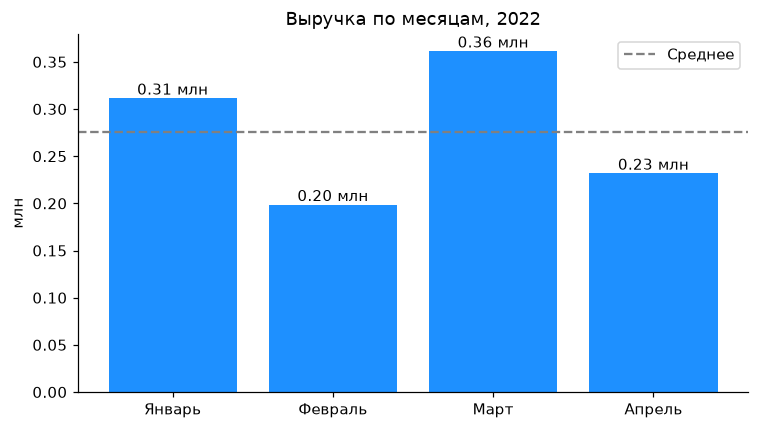

In [14]:
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110                # чёткость картинки
plt.rcParams["axes.spines.top"] = False          # убрать верхнюю рамку
plt.rcParams["axes.spines.right"] = False        # убрать правую рамку
IMG = "../images/"                               # куда сохранять картинки

months = ["Январь", "Февраль", "Март", "Апрель"]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(months, monthly.values / 1e6, color="#1E90FF")
ax.axhline(monthly.mean() / 1e6, linestyle="--", color="gray", label="Среднее")
ax.bar_label(bars, fmt="%.2f млн")
ax.set_title("Выручка по месяцам, 2022")
ax.set_ylabel("млн")
ax.legend()
plt.tight_layout()
plt.savefig(IMG + "01_monthly_revenue.png")
plt.show()

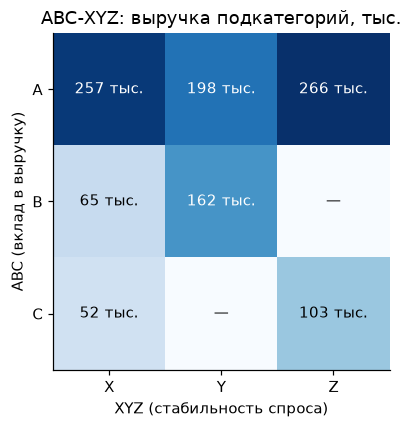

In [15]:
matrix = pd.crosstab(sub["ABC"], sub["XYZ"], values=sub["Выручка"], aggfunc="sum").fillna(0) / 1000
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(matrix.values, cmap="Blues")
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix.values[i, j]
        ax.text(j, i, f"{v:.0f} тыс." if v > 0 else "—", ha="center", va="center",
                color="white" if v > matrix.values.max() / 2 else "black")
ax.set_title("ABC-XYZ: выручка подкатегорий, тыс.")
ax.set_xlabel("XYZ (стабильность спроса)")
ax.set_ylabel("ABC (вклад в выручку)")
plt.tight_layout()
plt.savefig(IMG + "02_abc_xyz_matrix.png")
plt.show()

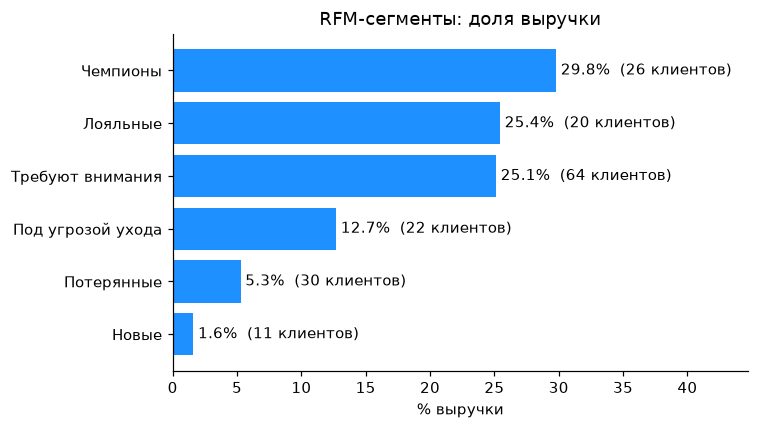

In [16]:
seg_sorted = seg.sort_values("Доля выручки, %")
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(seg_sorted.index, seg_sorted["Доля выручки, %"], color="#1E90FF")
ax.bar_label(bars, labels=[f"{p:.1f}%  ({n} клиентов)"
                           for p, n in zip(seg_sorted["Доля выручки, %"], seg_sorted["Клиентов"])],
             padding=3)
ax.set_title("RFM-сегменты: доля выручки")
ax.set_xlabel("% выручки")
ax.set_xlim(0, seg_sorted["Доля выручки, %"].max() * 1.5)
plt.tight_layout()
plt.savefig(IMG + "03_rfm_segments.png")
plt.show()

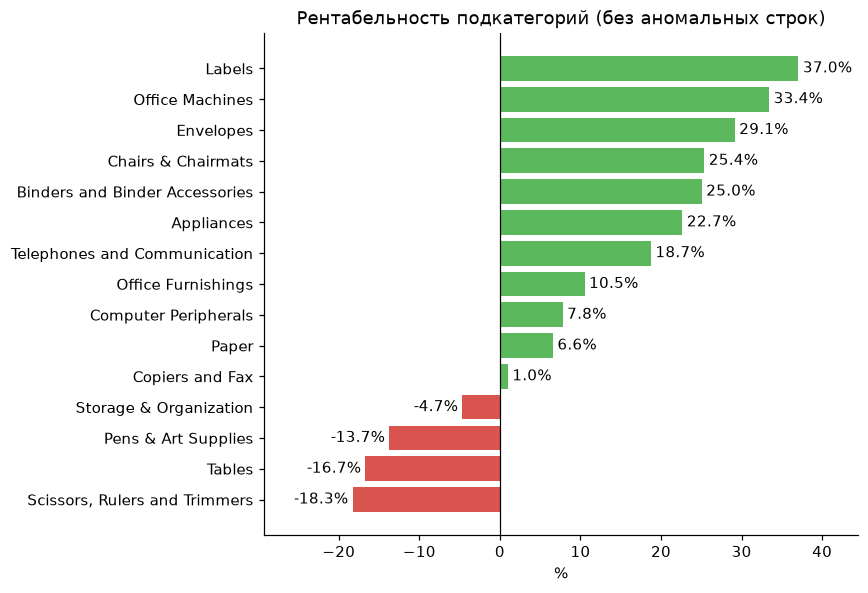

In [17]:
u = unit.sort_values("Рентабельность, %")
colors = ["#D9534F" if v < 0 else "#5CB85C" for v in u["Рентабельность, %"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(u.index, u["Рентабельность, %"], color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(u["Рентабельность, %"].min() * 1.6, u["Рентабельность, %"].max() * 1.2)
ax.set_title("Рентабельность подкатегорий (без аномальных строк)")
ax.set_xlabel("%")
plt.tight_layout()
plt.savefig(IMG + "04_margin_by_subcategory.png")
plt.show()

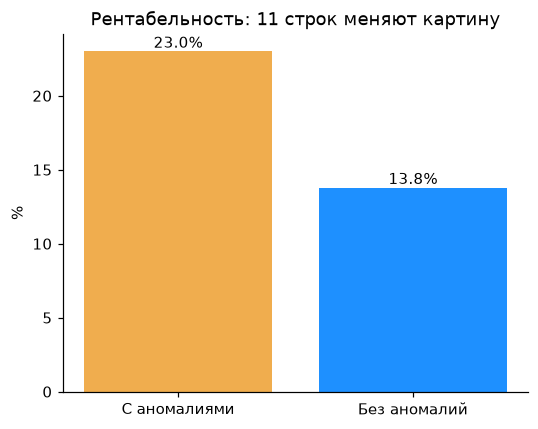

In [18]:
fig, ax = plt.subplots(figsize=(5, 4))
vals = compare.loc["Рентабельность, %"]
bars = ax.bar(vals.index, vals.values, color=["#F0AD4E", "#1E90FF"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title("Рентабельность: 11 строк меняют картину")
ax.set_ylabel("%")
plt.tight_layout()
plt.savefig(IMG + "05_anomalies_effect.png")
plt.show()